# Shared Reliable-Cohort Explainability: Congruent vs Incongruent Pure

This notebook interprets the C vs IP task using a shared reliable-subject cohort. The goal is not to explain every trained model on every subject; the goal is to avoid interpreting noise while still comparing all 10 model families on the same subjects.

The contrast asks whether EEG contains decodable structure related to conflict between congruent stimulation and incongruent trials that still resolve into a pure percept. Because the overall decoding results are weak, the notebook uses performance as a gatekeeper: models and subjects are kept visible, but strong interpretive claims are only attached to reliable evidence.

Main outputs:

- `selected_interpretability_subjects_c_vs_ip.csv`: the shared subjects used for all model maps.
- Spatial topomaps and temporal saliency curves for all 10 models.
- Peak-time model-minus-average topomaps for comparing model behavior.
- An experimental performance-weighted consensus diagnostic, clearly separated from thesis-grade evidence.


In [5]:
# Unified Environment Setup (Local, Colab, Kaggle)
import os
import sys
import warnings
from pathlib import Path

IS_KAGGLE = False
IS_COLAB = (not IS_KAGGLE) and ("google.colab" in sys.modules or "COLAB_GPU" in os.environ)
IN_COLAB = IS_COLAB

if IS_KAGGLE:
    print("Detected Kaggle environment. Installing dependencies...")
    !pip install -q mne seaborn scikit-learn
elif IS_COLAB:
    print("Detected Google Colab environment. Installing dependencies...")
    !pip install -q mne seaborn scikit-learn
    from google.colab import drive
    drive.mount("/content/drive")

try:
    NOTEBOOK_DIR = Path(__file__).resolve().parent
except NameError:
    NOTEBOOK_DIR = Path.cwd()

if IS_KAGGLE:
    dataset_root = None
    for root, dirs, files in os.walk("/kaggle/input"):
        if "br_analysis" in dirs:
            dataset_root = Path(root)
            break
    SRC_DIR = dataset_root if dataset_root else Path("/kaggle/input/nilsduranlaplaza/datasets/tfg-nils-2026-dataset")
elif IS_COLAB:
    SRC_DIR = Path("/content/drive/MyDrive/TFG_Nils_2026/03_Codi")
else:
    SRC_DIR = NOTEBOOK_DIR.parent.parent / "src"
    if not (SRC_DIR / "br_analysis" / "__init__.py").exists():
        SRC_DIR = NOTEBOOK_DIR.parent

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

try:
    from IPython import get_ipython
    ipy = get_ipython()
    if ipy is not None:
        ipy.run_line_magic("load_ext", "autoreload")
        ipy.run_line_magic("autoreload", "2")
except Exception:
    pass


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from br_analysis import ProjectPaths, detect_project_paths, get_task_config
from br_analysis.explainability import (
    MODEL_COLORS,
    MODEL_LABELS,
    MODEL_ORDER,
    OOF_CACHE_VERSION,
    build_context,
    build_evidence_table,
    convergence_table,
    consensus_diagnostic,
    evidence_pyramid,
    load_oof_predictions,
    model_interpretation_table,
    plot_consensus_diagnostic,
    plot_peak_time_difference_topomaps,
    plot_shared_cohort_spatial_topomaps,
    plot_shared_cohort_temporal_attribution,
    selected_cohort_model_evidence,
    selected_subject_ids,
    plot_convergence,
    plot_evidence_overview,
    save_tables,
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
print(f"Using source directory: {SRC_DIR}")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Using source directory: c:\Users\nils\Documents\Universitat\TFG\src


In [6]:
TASK_TAG = "c_vs_ip"
TASK_TAG_DISPLAY = f"{TASK_TAG.split('_vs_')[0].upper()} vs {TASK_TAG.split('_vs_')[1].upper()}"


def resolve_project_paths(analysis_name):
    """Resolve the data/output project using local workspace candidates before external Drive defaults."""
    candidates = []
    if IS_COLAB:
        candidates.append(Path("/content/drive/MyDrive/TFG_Nils_2026"))
    for base in [NOTEBOOK_DIR, *NOTEBOOK_DIR.parents, Path.cwd(), *Path.cwd().parents]:
        candidates.extend([base / "TFG_Nils_2026", base.parent / "TFG_Nils_2026"])

    seen = set()
    for project_dir in candidates:
        project_dir = Path(project_dir)
        key = str(project_dir).lower()
        if key in seen:
            continue
        seen.add(key)
        analysis_candidates = [p for p in project_dir.glob("04_An*lisi") if p.is_dir()]
        analysis_root = analysis_candidates[0] if analysis_candidates else project_dir / "04_An?lisi"
        cache_check_dir = analysis_root / "cross_model_comparison" / "cache"
        if analysis_root.exists() and cache_check_dir.exists() and any(cache_check_dir.glob("*.npz")):
            fixed_paths = ProjectPaths(
                project_dir=project_dir,
                data_dir=project_dir / "02_Data" / "01_Preprocessed_epochs",
                analysis_root=analysis_root,
                analysis_dir=analysis_root / analysis_name,
                cache_dir=analysis_root / analysis_name / "cache",
                tables_dir=analysis_root / analysis_name / "tables",
                figures_dir=analysis_root / analysis_name / "figures",
            )
            fixed_paths.ensure()
            return fixed_paths

    return detect_project_paths(analysis_name, in_colab=IN_COLAB, in_kaggle=IS_KAGGLE)


ANALYSIS_NAME = f"explainability_{TASK_TAG}"
paths = resolve_project_paths(ANALYSIS_NAME)
task = get_task_config(TASK_TAG, paths.analysis_root)
context = build_context(TASK_TAG, paths, task)

print(f"Project directory: {paths.project_dir}")
print(f"Analysis root: {paths.analysis_root}")
print(f"Notebook outputs: {paths.analysis_dir}")
print(f"Task: {context.display_name} ({context.class_0} vs {context.class_1})")
print(f"Expected cache version: {OOF_CACHE_VERSION}")

Project directory: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026
Analysis root: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi
Notebook outputs: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\explainability_c_vs_ip
Task: Congruent vs Incongruent Pure (Congruent vs Incongruent_Pure)
Expected cache version: stratified_group_kfold_holdout_v1


## 1. Task framing and expected neural hypotheses

This notebook is a sensor-level interpretability synthesis. It does not try to localize cortical sources; it asks whether the models rely on plausible EEG sensor patterns and time windows when they decode this task.

Two constraints guide the interpretation:

- **Performance first:** attribution maps are only scientifically useful when the corresponding model shows above-chance decoding evidence.
- **Shared subjects for comparison:** all 10 models are interpreted on the same reliable subject cohort for this task, so differences between maps are more likely to reflect model behavior rather than a different subject mix.

**Expected pattern for C vs IP.** Evidence is expected to be weak but, if real, should align with distributed conflict-related covariance plus frontal theta and posterior alpha structure. The strongest thesis claim should come from methods that are above chance, stable across subjects, and compatible with sensor-level frontal theta / posterior alpha hypotheses.


## 2. Performance evidence and shared reliable-cohort selection

The first step is to decide which subjects are worth interpreting. This notebook ranks subjects using fresh out-of-fold predictions from every usable model, then selects one shared cohort for all model families.

Selection rule:

- Compute each subject's mean accuracy across usable models.
- Count how many models reach `accuracy >= 0.55` for that subject.
- Rank subjects by number of above-threshold models, then by mean accuracy.
- Mark a subject as reliable when mean balanced accuracy is at least `0.55` and either at least three usable models, or at least 30% of available models, clear `0.55`.
- Select up to 10 reliable subjects when shared evidence is available; if fewer than five subjects pass the reliability rule, keep the reliable core and supplement up to five only as low-confidence diagnostic subjects.

The selected cohort is saved as `selected_interpretability_subjects_<task>.csv`. If the table is empty, the local runtime does not currently have the fresh OOF caches mounted/generated; the notebook is still structurally valid and will populate once those artifacts are available.


In [7]:
from br_analysis.explainability import get_model_specific_subjects

evidence, diagnostics = build_evidence_table(paths, task, TASK_TAG)
selected_cohort = diagnostics["selected_cohort"]
selected_subjects = selected_subject_ids(selected_cohort)
evidence = selected_cohort_model_evidence(evidence, diagnostics["subjects"], selected_subjects)
pyramid = evidence_pyramid(evidence)

# Model-specific subject filtering to eliminate chance-level noise in explainability maps (with 51% fallback)
threshold = 0.55 if TASK_TAG == "c_vs_ip" else 0.53
model_specific_subjects = get_model_specific_subjects(
    diagnostics["subjects"], selected_subjects, threshold, fallback_threshold=0.51
)
convergence = convergence_table(
    evidence,
    paths,
    task,
    TASK_TAG,
    subjects=model_specific_subjects,
    weight_col="Selected cohort reliability weight",
)
consensus_table, consensus_vectors = consensus_diagnostic(
    evidence,
    paths,
    task,
    TASK_TAG,
    subjects=model_specific_subjects,
    df_subject=diagnostics["subjects"],
)
save_tables(
    paths,
    TASK_TAG,
    evidence,
    pyramid,
    convergence,
    selected_cohort=selected_cohort,
    consensus=consensus_table,
)

display_cols = [
    "Display",
    "Family",
    "Mean accuracy",
    "Selected cohort mean accuracy",
    "Selected cohort reliability weight",
    "N subjects",
    "Selected cohort N subjects",
    "Final holdout accuracy",
    "Chance/permutation status",
    "Attribution availability",
    "Attribution stability",
    "Confound risk level",
    "Thesis-use recommendation",
]

evidence_display = evidence[display_cols].copy()
for col in [
    "Mean accuracy",
    "Selected cohort mean accuracy",
    "Selected cohort reliability weight",
    "Final holdout accuracy",
]:
    evidence_display[col] = evidence_display[col].map(lambda x: np.nan if pd.isna(x) else round(float(x), 4))

display(evidence_display)
cohort_summary = pd.DataFrame(
    [
        {
            "Metric": "Selected subjects",
            "Value": ", ".join(map(str, selected_subjects)) if selected_subjects else "none available",
        },
        {"Metric": "Tables directory", "Value": str(paths.tables_dir)},
    ]
)
display(cohort_summary)

,Display,Family,Mean accuracy,Selected cohort mean accuracy,Selected cohort reliability weight,N subjects,Selected cohort N subjects,Final holdout accuracy,Chance/permutation status,Attribution availability,Attribution stability,Confound risk level,Thesis-use recommendation
0,LR theta (FCz),targeted classical,0.5000,0.5171,0.0171,24,5,0.5092,not above chance,available_feature_definition,high_by_design,medium-high: near chance despite interpretable...,discard as evidence; keep as diagnostic
1,LR alpha (Oz),targeted classical,0.5349,0.5998,0.0998,24,5,0.5448,near chance / weak positive,available_feature_definition,high_by_design,medium: weak decoding margin,exploratory supporting evidence
2,Riemann TS-LDA,covariance classical,0.5637,0.6409,0.1409,24,5,0.5884,above practical chance,available_feature_definition,structural_not_fold_estimated,medium: EEG subject/time confounds still requi...,strong/moderate thesis evidence
3,Experiment-guided,hypothesis-guided,0.5566,0.6576,0.1576,24,5,0.5781,above practical chance,available_feature_definition,structural_with_circularity_risk,medium-high: cluster-selection circularity risk,exploratory supporting evidence
4,SVC clustering,classical SVC / cluster-restricted,0.5527,0.6106,0.1106,24,5,0.5679,above practical chance,available_feature_definition,structural_with_circularity_risk,medium-high: cluster-selection circularity risk,exploratory supporting evidence
5,EEGNet agnostic,deep CNN,0.5309,0.5601,0.0601,24,5,0.5321,near chance / weak positive,available_saliency_cache,0.044696,medium: weak decoding margin,exploratory supporting evidence
6,EEGNet clustering,deep CNN / cluster-restricted,0.5100,0.4874,0.0000,24,5,0.5037,near chance / weak positive,available_saliency_cache,0.953281,medium-high: cluster-selection circularity risk,weak exploratory evidence
7,ST-GNN,graph deep learning,0.5178,0.5377,0.0377,24,5,0.5305,near chance / weak positive,available_saliency_cache,0.237456,medium: weak decoding margin,weak exploratory evidence
8,ST-EEGFormer,transformer,0.4894,0.5316,0.0316,24,5,0.5253,not above chance,available_saliency_cache,0.873151,medium-high: adaptation/cache sensitivity,discard as evidence; keep as diagnostic
9,LaBraM,foundation model,0.4864,0.5042,0.0042,24,5,0.5260,not above chance,available_saliency_cache,0.975511,medium-high: adaptation/cache sensitivity,discard as evidence; keep as diagnostic


,Metric,Value
0,Selected subjects,"P003, P066, P017, P057, P030"
1,Tables directory,H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8...


### Artifact freshness and selected subjects

This diagnostic block makes missing evidence visible instead of silently dropping models. A model is usable only when its OOF cache matches the expected cache version and grouped-development validation strategy.

The cohort table below is the critical one for the workflow. The same selected subjects are reused for all 10 models in the later spatial, temporal, and consensus plots. `selected_cohort_role` separates reliable subjects from any low-confidence diagnostic supplements.


In [8]:
cache_status = diagnostics["cache_status"].copy()
display(cache_status[["Model", "OOF cache", "OOF usable", "OOF status"]])

subjects = diagnostics["subjects"]
artifact_summary = pd.DataFrame([{"Metric": "Subjects with at least one fresh model artifact", "Value": len(subjects)}])
display(artifact_summary)
if len(subjects):
    display(subjects.head())

if not selected_cohort.empty:
    cohort_display = selected_cohort.copy()
    for col in ["mean_accuracy"]:
        cohort_display[col] = cohort_display[col].map(lambda x: np.nan if pd.isna(x) else round(float(x), 4))
    display(cohort_display)

,Model,OOF cache,OOF usable,OOF status
0,LR_theta,oof_predictions_c_vs_i_FCz_theta_Oz_alpha.npz,True,ok
1,LR_alpha,oof_predictions_c_vs_i_FCz_theta_Oz_alpha.npz,True,ok
2,Riemann,oof_predictions_c_vs_i_riemann_fused.npz,True,ok
3,Experiment_Guided,oof_predictions_c_vs_ip_experiment_guided.npz,True,ok
4,EEGNet_Agnostic,oof_predictions_c_vs_ip_eegnet_agnostic.npz,True,ok
5,EEGNet_Clustering,oof_predictions_c_vs_ip_eegnet_clustering.npz,True,ok
6,SVC_Clustering,oof_predictions_c_vs_ip_svc_clustering.npz,True,ok
7,ST_GNN,oof_predictions_c_vs_ip_stgnn.npz,True,ok
8,ST_EEGFormer,oof_predictions_c_vs_ip_steegformer.npz,True,ok
9,LaBraM,oof_predictions_c_vs_ip_labram.npz,True,ok


,Metric,Value
0,Subjects with at least one fresh model artifact,24


,subject,LR_theta,LR_alpha,Riemann,Experiment_Guided,EEGNet_Agnostic,EEGNet_Clustering,SVC_Clustering,ST_GNN,ST_EEGFormer,LaBraM
0,P057,0.584783,0.626087,0.728696,0.728745,0.544534,0.490216,0.593455,0.438259,0.542848,0.465587
1,P003,0.576797,0.580108,0.626247,0.639032,0.539247,0.501075,0.628925,0.595376,0.592796,0.520860
2,P066,0.458333,0.632576,0.636364,0.642566,0.527789,0.517242,0.599460,0.599546,0.565464,0.481033
3,P002,0.539286,0.545238,0.505060,0.432768,0.521716,0.526551,0.554737,0.453815,0.516064,0.475086
4,P065,0.542698,0.585238,0.583492,0.521093,0.475543,0.485018,0.575165,0.540265,0.479939,0.538900


,subject,LR_theta,LR_alpha,Riemann,Experiment_Guided,SVC_Clustering,EEGNet_Agnostic,EEGNet_Clustering,ST_GNN,ST_EEGFormer,...,mean_accuracy,n_models_available,n_models_above_0_55,fraction_models_above_0_55,meets_reliable_subject_rule,candidate_rank,selected_rank,selected_for_interpretability,selected_cohort_role,selection_reason
0,P003,0.576797,0.580108,0.626247,0.639032,0.628925,0.539247,0.501075,0.595376,0.592796,...,0.5800,10,7,0.7,True,1,1.0,True,reliable,reliable_core_plus_low_confidence_diagnostic_s...
1,P066,0.458333,0.632576,0.636364,0.642566,0.599460,0.527789,0.517242,0.599546,0.565464,...,0.5660,10,6,0.6,True,2,2.0,True,reliable,reliable_core_plus_low_confidence_diagnostic_s...
2,P017,0.482220,0.607297,0.611187,0.638393,0.595982,0.615327,0.450893,0.581101,0.463542,...,0.5576,10,6,0.6,True,3,3.0,True,reliable,reliable_core_plus_low_confidence_diagnostic_s...
3,P057,0.584783,0.626087,0.728696,0.728745,0.593455,0.544534,0.490216,0.438259,0.542848,...,0.5743,10,5,0.5,True,4,4.0,True,reliable,reliable_core_plus_low_confidence_diagnostic_s...
4,P030,0.483282,0.552941,0.602167,0.639414,0.634965,0.573415,0.477568,0.474231,0.493141,...,0.5454,10,5,0.5,False,5,5.0,True,low_confidence_diagnostic,reliable_core_plus_low_confidence_diagnostic_s...
5,P058,0.530702,0.518246,0.679649,0.635996,0.609254,0.471323,0.546798,0.584975,0.458656,...,0.5417,10,4,0.4,False,6,NaN,False,not_selected,not_selected
6,P021,0.564067,0.551443,0.617056,0.540106,0.583305,0.491841,0.540021,0.420045,0.520268,...,0.5264,10,4,0.4,False,7,NaN,False,not_selected,not_selected
7,P013,0.487909,0.532242,0.570809,0.582677,0.551181,0.551181,0.484252,0.496063,0.433071,...,0.5170,10,4,0.4,False,8,NaN,False,not_selected,not_selected
8,P046,0.371212,0.578030,0.561364,0.565829,0.545248,0.516798,0.501513,0.554631,0.429782,...,0.5099,10,4,0.4,False,9,NaN,False,not_selected,not_selected
9,P065,0.542698,0.585238,0.583492,0.521093,0.575165,0.475543,0.485018,0.540265,0.479939,...,0.5327,10,3,0.3,False,10,NaN,False,not_selected,not_selected


### Performance overview

This figure summarizes model accuracy before any interpretation. The dashed line marks nominal chance.

A model close to chance can still be plotted as a diagnostic, but it should not become thesis evidence just because its saliency map looks visually plausible. The selected-cohort reliability weight used later is `max(selected_cohort_mean_accuracy - 0.5, 0)`.


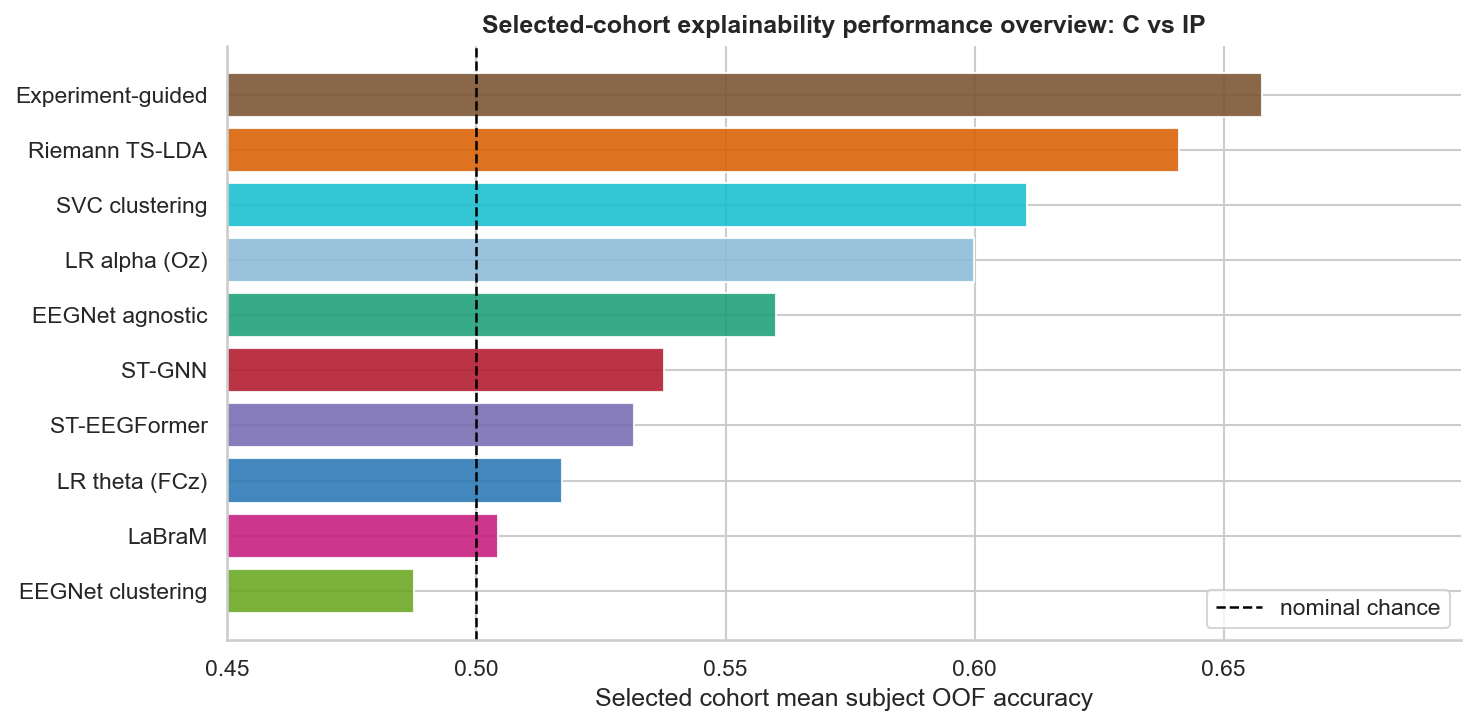

In [9]:
fig = plot_evidence_overview(
    evidence,
    TASK_TAG,
    save_path=paths.figures_dir / f"explainability_performance_overview_{TASK_TAG}.png",
)
if fig is not None:
    plt.show()

### Selected-cohort ROC and precision-recall diagnostics

ROC and precision-recall curves are computed only from fresh OOF prediction arrays, and now only for the selected shared cohort. This keeps the discrimination curves aligned with the same subjects used in the interpretability maps.

If no curves appear, it means the fresh OOF prediction caches are missing or stale in the current runtime.


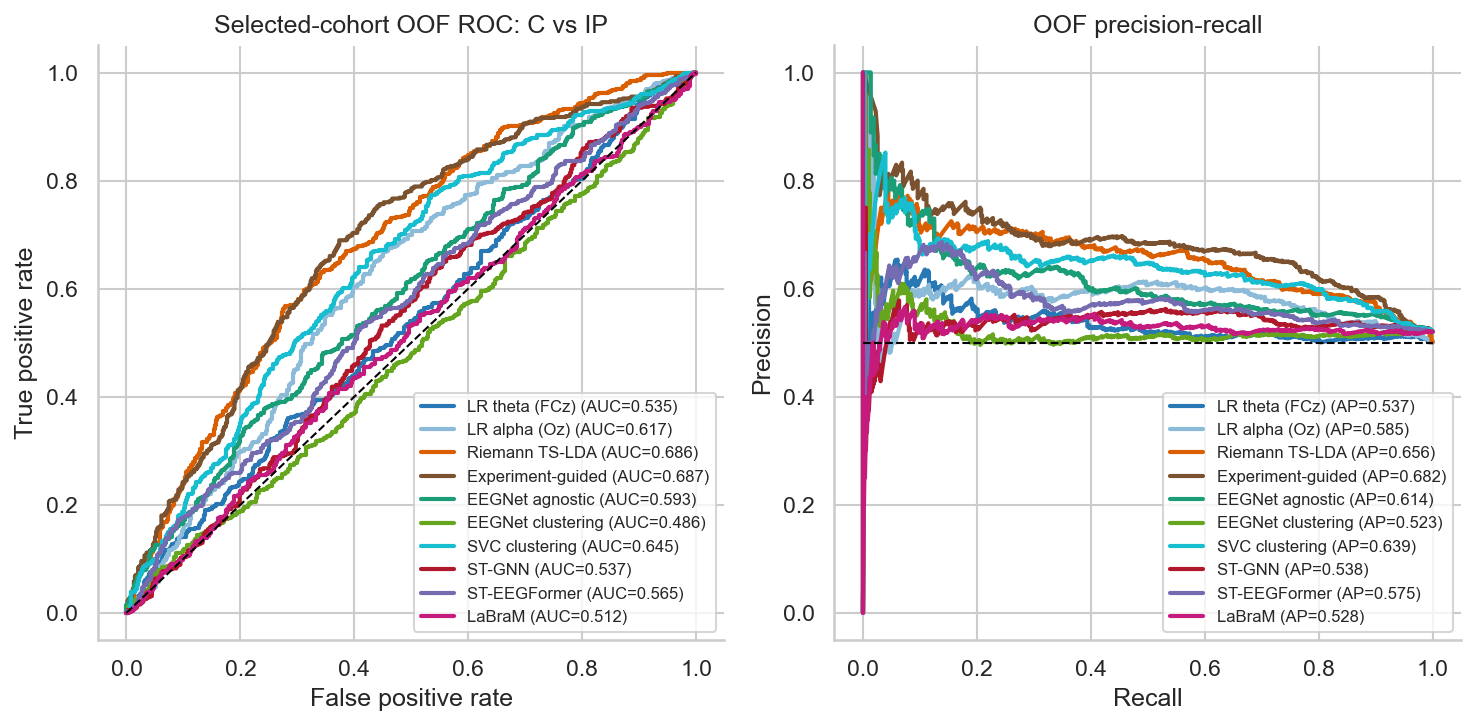

In [10]:
from sklearn.metrics import auc, average_precision_score, precision_recall_curve, roc_curve

model_predictions = load_oof_predictions(paths, task, TASK_TAG, subjects=selected_subjects)
if not model_predictions:
    roc_pr_status = pd.DataFrame(
        [{"Status": "skipped", "Reason": "No fresh OOF prediction arrays are available for the selected cohort."}]
    )
    display(roc_pr_status)
else:
    fig, axes = plt.subplots(1, 2, figsize=(10, 5), dpi=150)
    for model_name, preds in model_predictions.items():
        y_true = preds["y_true"]
        y_prob = preds["y_prob"]
        fpr, tpr, _ = roc_curve(y_true, y_prob)
        precision, recall, _ = precision_recall_curve(y_true, y_prob)
        axes[0].plot(
            fpr,
            tpr,
            lw=2,
            color=MODEL_COLORS.get(model_name, "#777777"),
            label=f"{MODEL_LABELS[model_name]} (AUC={auc(fpr, tpr):.3f})",
        )
        axes[1].plot(
            recall,
            precision,
            lw=2,
            color=MODEL_COLORS.get(model_name, "#777777"),
            label=f"{MODEL_LABELS[model_name]} (AP={average_precision_score(y_true, y_prob):.3f})",
        )
    axes[0].plot([0, 1], [0, 1], color="black", linestyle="--", linewidth=1)
    axes[0].set_title(f"Selected-cohort OOF ROC: {TASK_TAG_DISPLAY}")
    axes[0].set_xlabel("False positive rate")
    axes[0].set_ylabel("True positive rate")
    axes[0].legend(fontsize=8)
    axes[1].plot([0, 1], [0.5, 0.5], color="black", linestyle="--", linewidth=1)
    axes[1].set_title("OOF precision-recall")
    axes[1].set_xlabel("Recall")
    axes[1].set_ylabel("Precision")
    axes[1].legend(fontsize=8)
    sns.despine(fig=fig)
    fig.tight_layout()
    fig.savefig(paths.figures_dir / f"explainability_oof_roc_pr_{TASK_TAG}.png", dpi=150, bbox_inches="tight")
    plt.show()

## 3. Model-by-model interpretation

This table is the narrative checkpoint for the 10 models. It combines selected-cohort performance with attribution availability so each model has an explicit interpretation status.

A model can be useful in three different ways:

- **Evidence:** selected-cohort performance is meaningfully above chance and the attribution source is valid.
- **Diagnostic:** the model is plotted for comparison, but the reliability weight is weak or attribution is structural only.
- **Prediction-only:** fresh OOF predictions exist, but no saliency/IG/LRP/SHAP attribution has been exported for that model yet.

This avoids the earlier problem where missing DL saliency could look like a real zero-valued map.


In [11]:
family_view = model_interpretation_table(evidence)
for col in ["Selected cohort accuracy", "Reliability weight"]:
    family_view[col] = family_view[col].map(lambda x: np.nan if pd.isna(x) else round(float(x), 4))
display(family_view)

,Model,Family,Selected cohort accuracy,Reliability weight,Attribution status,Evidence interpretation,Attribution interpretation
0,LR theta (FCz),targeted classical,0.5171,0.0171,available_feature_definition,Weak diagnostic only; selected-cohort decoding...,"Structural/feature-defined attribution, normal..."
1,LR alpha (Oz),targeted classical,0.5998,0.0998,available_feature_definition,Interpretable with caution; selected-cohort de...,"Structural/feature-defined attribution, normal..."
2,Riemann TS-LDA,covariance classical,0.6409,0.1409,available_feature_definition,Interpretable with caution; selected-cohort de...,"Structural/feature-defined attribution, normal..."
3,Experiment-guided,hypothesis-guided,0.6576,0.1576,available_feature_definition,Interpretable with caution; selected-cohort de...,"Structural/feature-defined attribution, normal..."
4,SVC clustering,classical SVC / cluster-restricted,0.6106,0.1106,available_feature_definition,Interpretable with caution; selected-cohort de...,"Structural/feature-defined attribution, normal..."
5,EEGNet agnostic,deep CNN,0.5601,0.0601,available_saliency_cache,Interpretable with caution; selected-cohort de...,Cached model saliency is available and project...
6,EEGNet clustering,deep CNN / cluster-restricted,0.4874,0.0000,available_saliency_cache,Do not interpret as evidence; selected-cohort ...,Cached model saliency is available and project...
7,ST-GNN,graph deep learning,0.5377,0.0377,available_saliency_cache,Weak diagnostic only; selected-cohort decoding...,Cached model saliency is available and project...
8,ST-EEGFormer,transformer,0.5316,0.0316,available_saliency_cache,Weak diagnostic only; selected-cohort decoding...,Cached model saliency is available and project...
9,LaBraM,foundation model,0.5042,0.0042,available_saliency_cache,Weak diagnostic only; selected-cohort decoding...,Cached model saliency is available and project...


## 4. Cross-model convergence and shared-cohort maps

This section asks whether the models converge on plausible sensor-level evidence. For linear/classical models, the maps reflect feature definitions or structural model priors. For deep models, the maps use cached saliency summaries when available.

The important methodological choice is that the selected subjects do not change from model to model. Strong models may have more subjects above threshold outside this cohort, and weak models may have only a few, but the main maps stay comparable because every model is evaluated on the same task-level subject list. If a model performs poorly on the shared cohort, it remains visible with low or zero reliability weight rather than being replaced with easier model-specific subjects.


,Model,Display,Reliability weight,Attribution availability,Attribution stability,Frontal alignment,Temporal alignment,Parietal alignment,Occipital alignment,Weighted convergence contribution
0,LR_theta,LR theta (FCz),0.0171,available_feature_definition,high_by_design,1.0000,0.0000,0.0000,0.0000,0.0085
1,LR_alpha,LR alpha (Oz),0.0998,available_feature_definition,high_by_design,0.0000,0.0000,0.0000,1.0000,0.0499
2,Riemann,Riemann TS-LDA,0.1409,available_feature_definition,structural_not_fold_estimated,0.3636,0.0000,0.3636,0.2727,0.0448
3,Experiment_Guided,Experiment-guided,0.1576,available_feature_definition,structural_with_circularity_risk,0.1724,0.0000,0.5862,0.2414,0.0326
4,SVC_Clustering,SVC clustering,0.1106,available_feature_definition,structural_with_circularity_risk,0.1724,0.0000,0.5862,0.2414,0.0229
5,EEGNet_Agnostic,EEGNet agnostic,0.0601,available_saliency_cache,0.473619,0.3769,0.1023,0.3886,0.1322,0.0153
6,EEGNet_Clustering,EEGNet clustering,0.0000,available_saliency_cache,NaN,0.1499,0.0000,0.5783,0.2718,0.0000
7,ST_GNN,ST-GNN,0.0377,available_saliency_cache,0.327857,0.3794,0.1029,0.3817,0.1361,0.0097
8,ST_EEGFormer,ST-EEGFormer,0.0316,available_saliency_cache,0.87566,0.3697,0.1036,0.3951,0.1316,0.0079
9,LaBraM,LaBraM,0.0042,available_saliency_cache,0.985026,0.3034,0.0746,0.4195,0.2025,0.0011


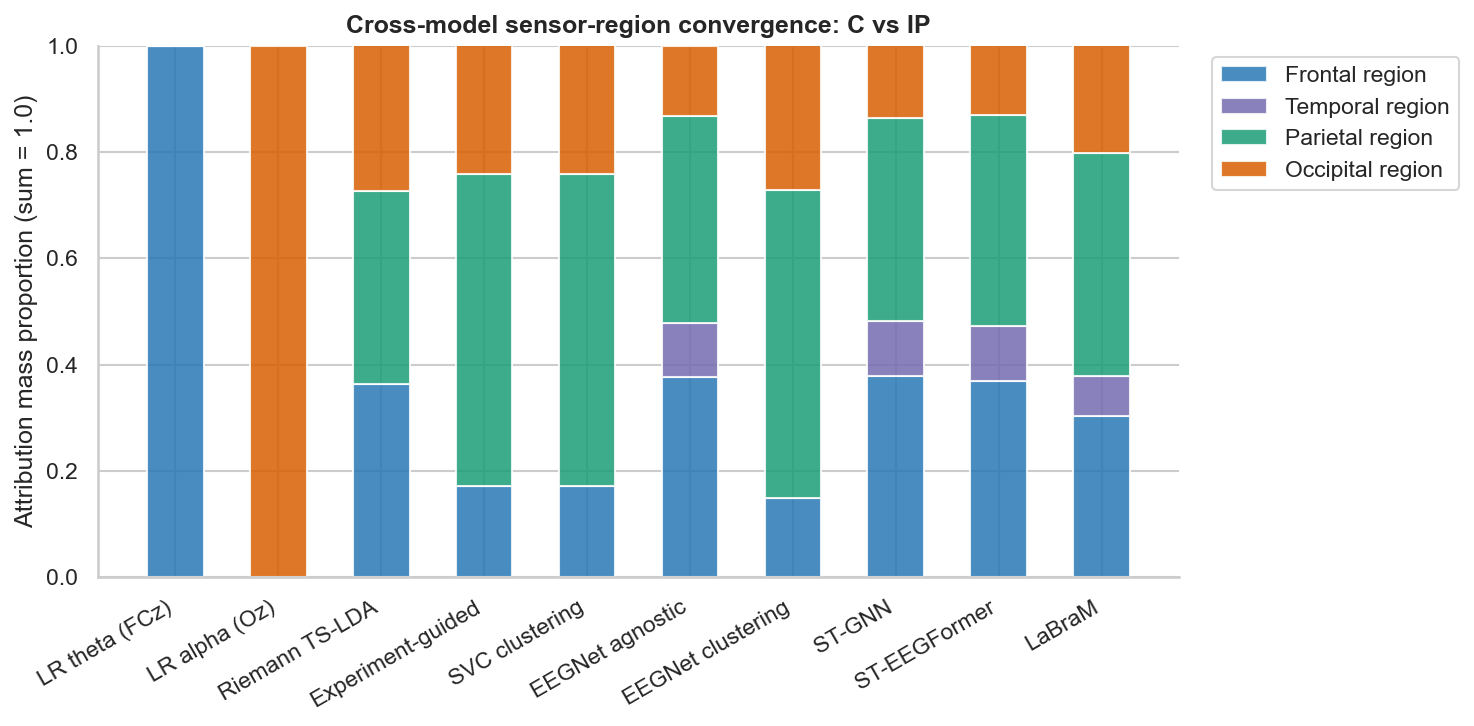

In [12]:
    conv_display = convergence.copy()
    for col in [
        'Reliability weight',
        'Frontal alignment',
        'Temporal alignment',
        'Parietal alignment',
        'Occipital alignment',
        'Weighted convergence contribution',
    ]:
        if col in conv_display.columns:
            conv_display[col] = conv_display[col].map(lambda x: round(float(x), 4))
    display(conv_display)
    
    fig = plot_convergence(
        convergence,
        TASK_TAG,
        save_path=paths.figures_dir / f'explainability_convergence_{TASK_TAG}.png',
    )
    plt.show()


### Shared-cohort spatial and temporal maps

These are the main interpretability figures.

- Spatial topomaps show each model's electrode importance on the shared cohort.
- Temporal saliency curves show when each model places the most importance during the analysis window.
- Low-weight models are still plotted, but their lines/maps should be read as diagnostics rather than evidence.

This is the safest comparison for linear vs non-linear models because every model is judged on the same subjects.


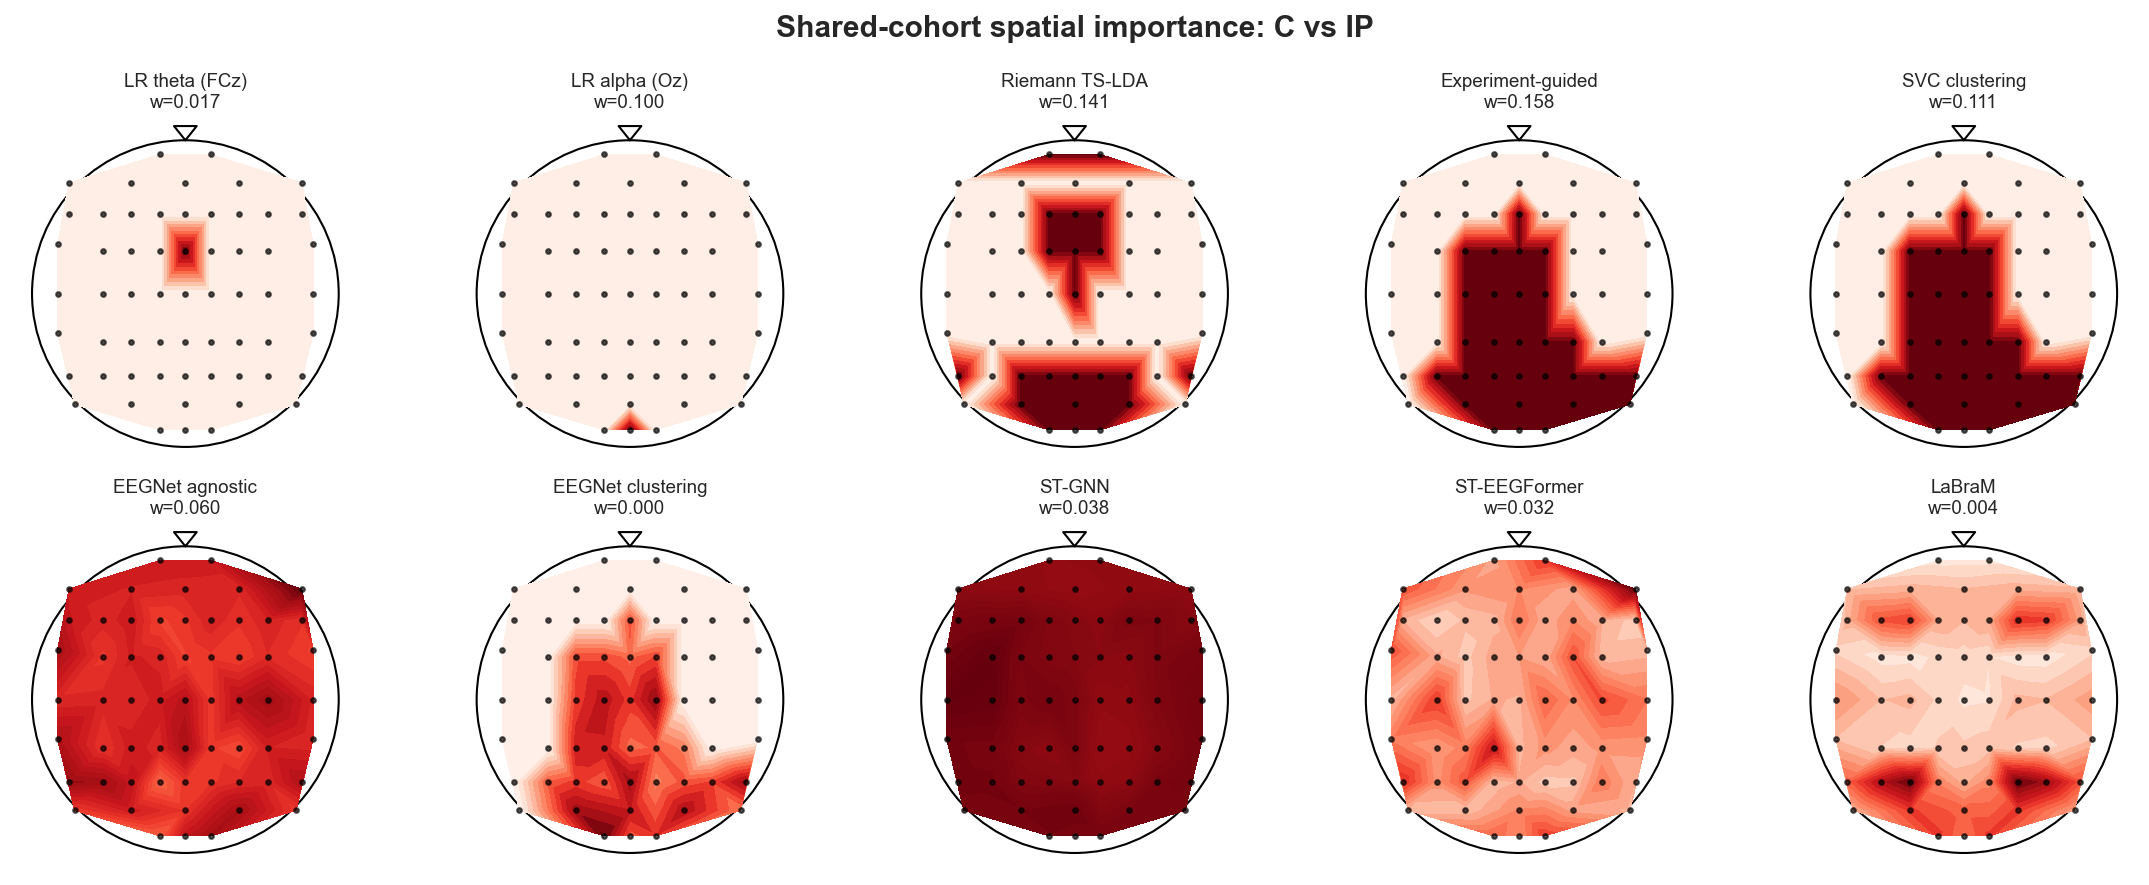

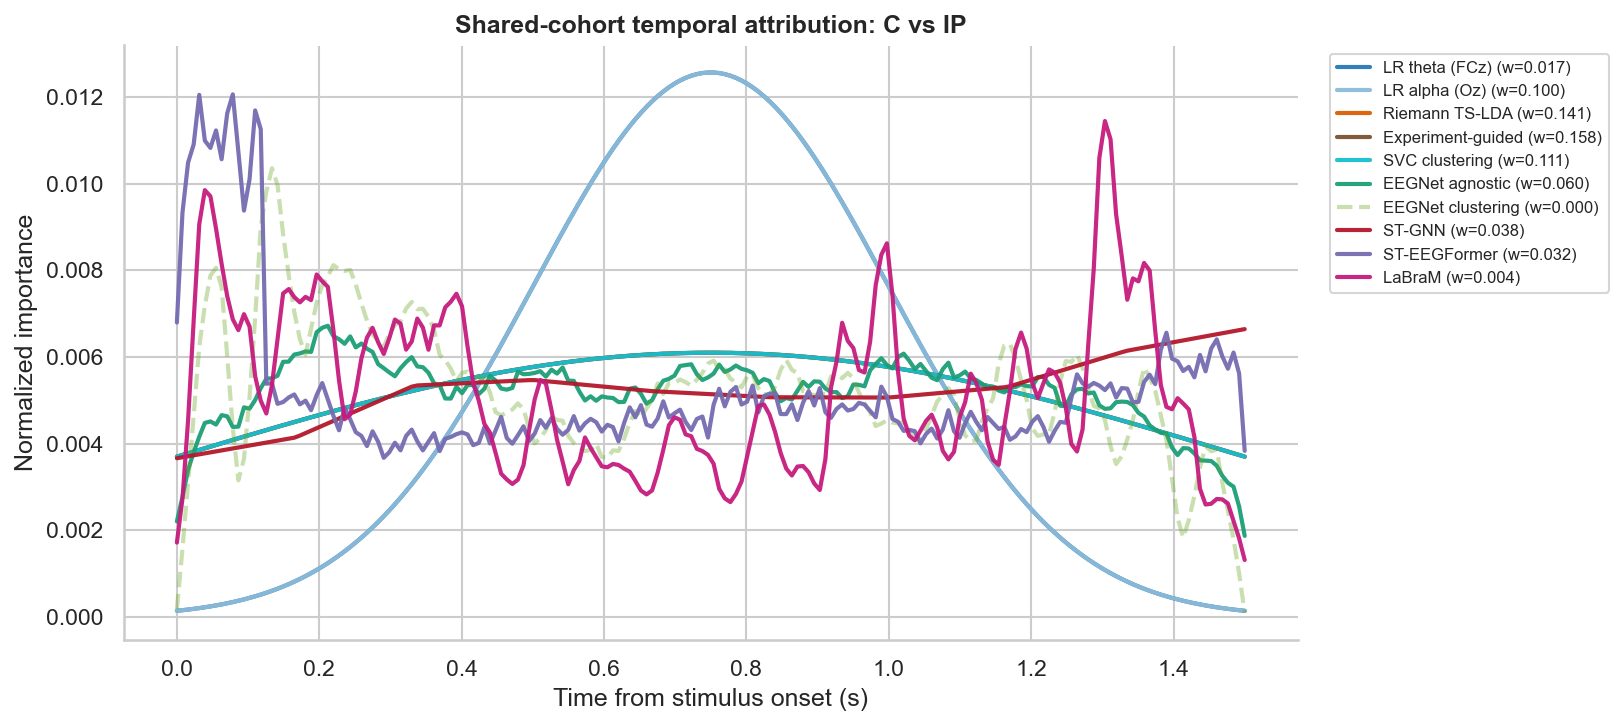

In [13]:
fig = plot_shared_cohort_spatial_topomaps(
    evidence,
    paths,
    task,
    TASK_TAG,
    subjects=model_specific_subjects,
    save_path=paths.figures_dir / f"shared_cohort_spatial_topomaps_{TASK_TAG}.png",
)
plt.show()

fig = plot_shared_cohort_temporal_attribution(
    evidence,
    paths,
    task,
    TASK_TAG,
    subjects=model_specific_subjects,
    save_path=paths.figures_dir / f"shared_cohort_temporal_attribution_{TASK_TAG}.png",
)
plt.show()

### Peak-time model-minus-average maps

These plots summarize how each model differs from the cross-model average at its strongest temporal point.

The current saliency artifacts store spatial and temporal summaries separately, not full channel-by-time tensors. Because of that, this section uses each model's spatial pattern scaled at its temporal peak. It is a compact model-comparison diagnostic, not a claim that the exact full spatiotemporal attribution tensor has been recovered.


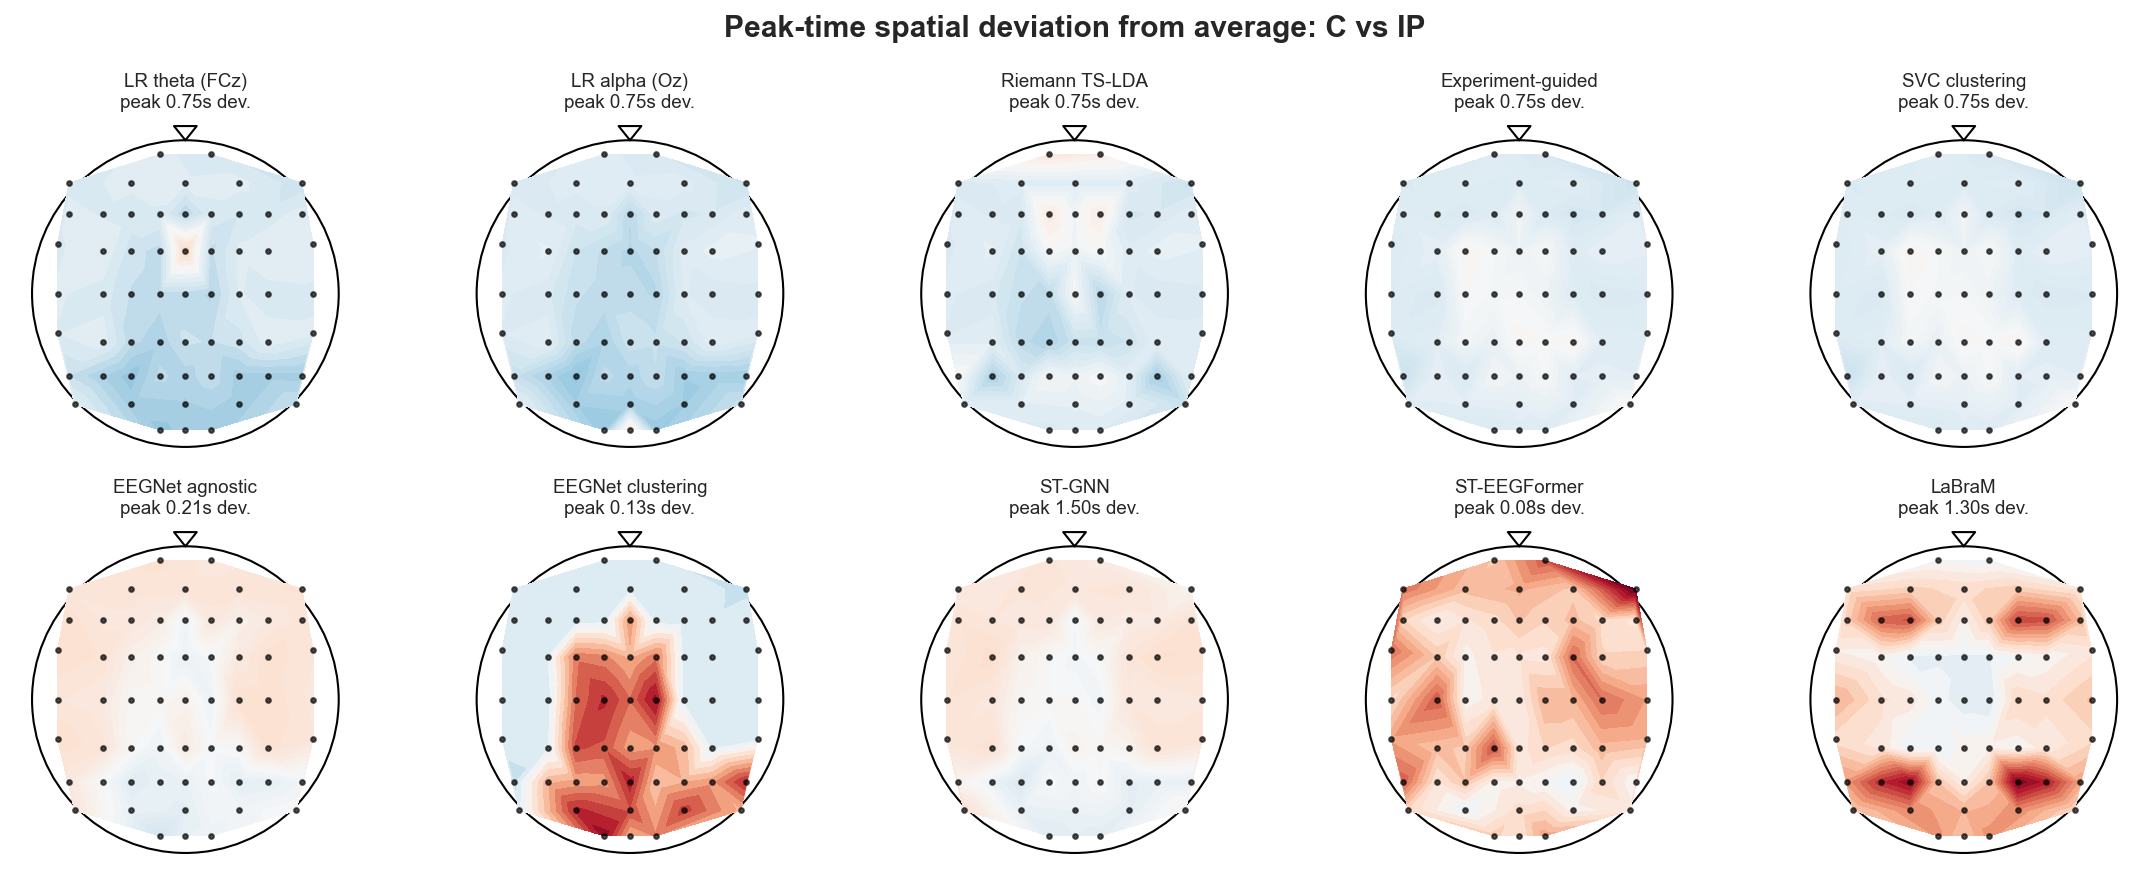

In [14]:
fig = plot_peak_time_difference_topomaps(
    evidence,
    paths,
    task,
    TASK_TAG,
    subjects=model_specific_subjects,
    save_path=paths.figures_dir / f"peak_time_spatial_deviation_{TASK_TAG}.png",
)
if fig is not None:
    plt.show()

## 5. Experimental consensus diagnostic

This section builds the optional performance-weighted consensus map.

The weighting is intentionally simple: models receive weight only for selected-cohort accuracy above chance. The result is useful as an exploratory diagnostic of cross-model agreement, but it should not be described as a new global model unless it later receives its own validation.

The weighted consensus is compared with an unweighted consensus. If at least five selected subjects are available, the notebook also reports a bootstrap stability estimate for the selected-cohort mean accuracy.


,Model,Display,Selected cohort reliability weight,Attribution availability,Included in weighted consensus,Temporal peak time (s),Bootstrap selected-subject mean-accuracy std
0,LR_theta,LR theta (FCz),0.0171,available_feature_definition,True,0.7461,0.0057
1,LR_alpha,LR alpha (Oz),0.0998,available_feature_definition,True,0.7461,0.0057
2,Riemann,Riemann TS-LDA,0.1409,available_feature_definition,True,0.7461,0.0057
3,Experiment_Guided,Experiment-guided,0.1576,available_feature_definition,True,0.7461,0.0057
4,SVC_Clustering,SVC clustering,0.1106,available_feature_definition,True,0.7461,0.0057
5,EEGNet_Agnostic,EEGNet agnostic,0.0601,available_saliency_cache,True,0.2120,0.0057
6,EEGNet_Clustering,EEGNet clustering,0.0000,available_saliency_cache,False,0.1335,0.0057
7,ST_GNN,ST-GNN,0.0377,available_saliency_cache,True,1.5000,0.0057
8,ST_EEGFormer,ST-EEGFormer,0.0316,available_saliency_cache,True,0.0785,0.0057
9,LaBraM,LaBraM,0.0042,available_saliency_cache,True,1.3037,0.0057


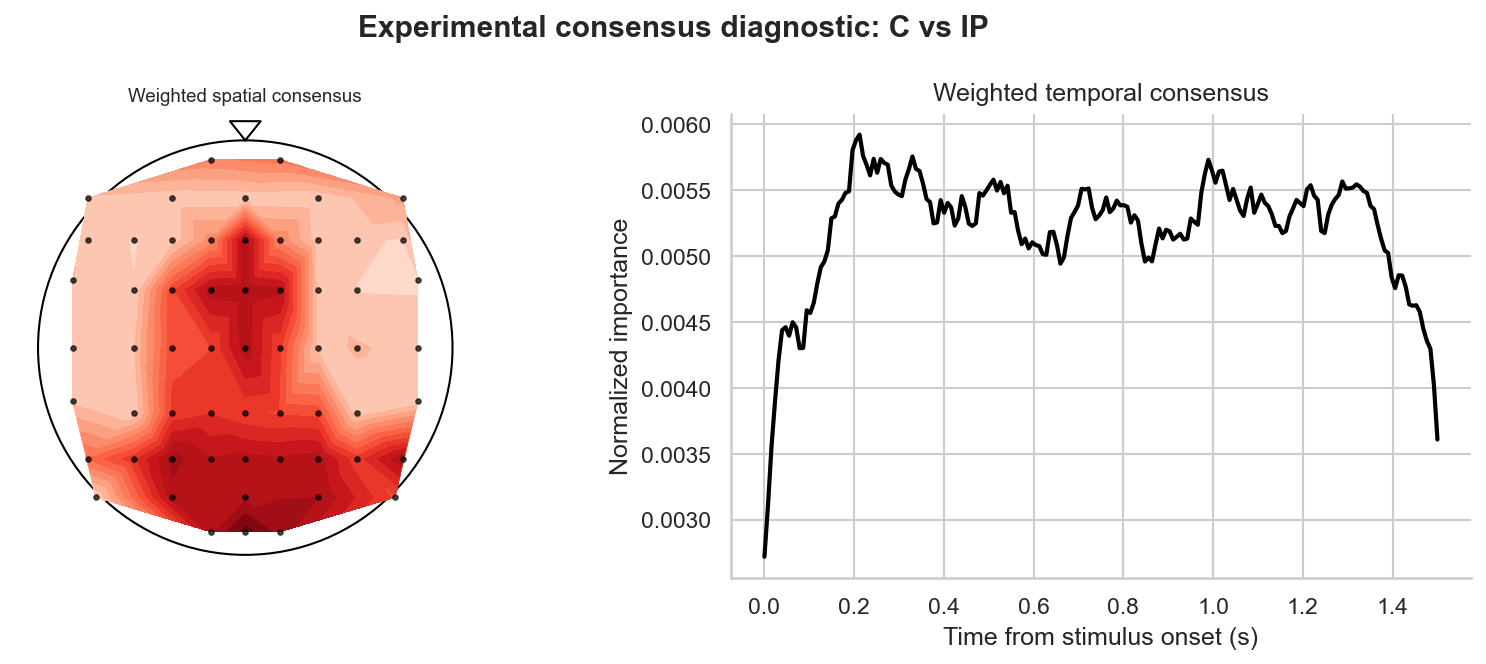

In [15]:
consensus_display = consensus_table.copy()
for col in [
    "Selected cohort reliability weight",
    "Temporal peak time (s)",
    "Bootstrap selected-subject mean-accuracy std",
]:
    if col in consensus_display.columns:
        consensus_display[col] = consensus_display[col].map(lambda x: np.nan if pd.isna(x) else round(float(x), 4))
display(consensus_display)

# Generate and display the global performance-weighted consensus diagnostic
fig = plot_consensus_diagnostic(
    consensus_vectors,
    task,
    TASK_TAG,
    save_path=paths.figures_dir / f"experimental_consensus_diagnostic_{TASK_TAG}.png",
)
plt.show()

## 6. Confound diagnostics

This section lists the main reasons an attractive map might still be misleading.

The key risks are subject identity, temporal drift, class imbalance, cluster-selection circularity, stale caches, and overinterpretation of sensor topographies. The notebook keeps weak or stale models visible so the final interpretation can say clearly what is evidence, what is diagnostic, and what should be regenerated.


In [16]:
confound_cols = [
    "Display",
    "OOF usable",
    "OOF status",
    "Final holdout status",
    "Chance/permutation status",
    "Confound risk level",
    "Thesis-use recommendation",
]
display(evidence[confound_cols])

,Display,OOF usable,OOF status,Final holdout status,Chance/permutation status,Confound risk level,Thesis-use recommendation
0,LR theta (FCz),True,ok,ok,not above chance,medium-high: near chance despite interpretable...,discard as evidence; keep as diagnostic
1,LR alpha (Oz),True,ok,ok,near chance / weak positive,medium: weak decoding margin,exploratory supporting evidence
2,Riemann TS-LDA,True,ok,ok,above practical chance,medium: EEG subject/time confounds still requi...,strong/moderate thesis evidence
3,Experiment-guided,True,ok,ok,above practical chance,medium-high: cluster-selection circularity risk,exploratory supporting evidence
4,SVC clustering,True,ok,ok,above practical chance,medium-high: cluster-selection circularity risk,exploratory supporting evidence
5,EEGNet agnostic,True,ok,ok,near chance / weak positive,medium: weak decoding margin,exploratory supporting evidence
6,EEGNet clustering,True,ok,ok,near chance / weak positive,medium-high: cluster-selection circularity risk,weak exploratory evidence
7,ST-GNN,True,ok,ok,near chance / weak positive,medium: weak decoding margin,weak exploratory evidence
8,ST-EEGFormer,True,ok,ok,not above chance,medium-high: adaptation/cache sensitivity,discard as evidence; keep as diagnostic
9,LaBraM,True,ok,ok,not above chance,medium-high: adaptation/cache sensitivity,discard as evidence; keep as diagnostic


## 7. Evidence pyramid

The evidence pyramid turns the previous diagnostics into a practical thesis-use ranking.

Use the top tier as the safest material for the thesis narrative. Treat weak or exploratory rows as supporting context only. Rows marked for discard/regeneration should not be used as scientific evidence until the underlying artifacts are refreshed.


In [17]:
display(pyramid)

,Display,Model,Mean accuracy,Chance/permutation status,Confound risk level,Thesis-use recommendation,Evidence tier
2,Riemann TS-LDA,Riemann,0.563746,above practical chance,medium: EEG subject/time confounds still requi...,strong/moderate thesis evidence,strongest evidence
0,LR theta (FCz),LR_theta,0.499984,not above chance,medium-high: near chance despite interpretable...,discard as evidence; keep as diagnostic,suspect / do not use as support
8,ST-EEGFormer,ST_EEGFormer,0.489440,not above chance,medium-high: adaptation/cache sensitivity,discard as evidence; keep as diagnostic,suspect / do not use as support
9,LaBraM,LaBraM,0.486396,not above chance,medium-high: adaptation/cache sensitivity,discard as evidence; keep as diagnostic,suspect / do not use as support
3,Experiment-guided,Experiment_Guided,0.556603,above practical chance,medium-high: cluster-selection circularity risk,exploratory supporting evidence,weaker evidence
4,SVC clustering,SVC_Clustering,0.552732,above practical chance,medium-high: cluster-selection circularity risk,exploratory supporting evidence,weaker evidence
1,LR alpha (Oz),LR_alpha,0.534856,near chance / weak positive,medium: weak decoding margin,exploratory supporting evidence,weaker evidence
5,EEGNet agnostic,EEGNet_Agnostic,0.530898,near chance / weak positive,medium: weak decoding margin,exploratory supporting evidence,weaker evidence
7,ST-GNN,ST_GNN,0.517753,near chance / weak positive,medium: weak decoding margin,weak exploratory evidence,weaker evidence
6,EEGNet clustering,EEGNet_Clustering,0.509976,near chance / weak positive,medium-high: cluster-selection circularity risk,weak exploratory evidence,weaker evidence


## 8. Final synthesis notes

Use the evidence, selected-cohort, convergence, and consensus tables above to write the final thesis interpretation. The defensible narrative should prioritize models with reliable selected-cohort decoding and available attribution summaries. Weak, stale, or prediction-only models should remain visible as diagnostics, but they should not be treated as positive interpretability evidence.
